# CardioFusion-XAI — FT-Transformer clinical / biomarker training

**Additional experiment notebook.** The original `biomarkers.ipynb` and `cardiac_biomarker_training.ipynb` are preserved unchanged. This notebook adds an independent FT-Transformer experiment so the existing GBDT/ensemble work and the FT-Transformer candidate can be compared later.

## Training design

- Four independent experts: Zheen, Framingham, UCI Heart Failure and MI Complications.
- No cross-dataset concatenation or assumed patient pairing.
- Each source has its own feature order, train-only imputation/scaling, model checkpoint and prediction files.
- Train/validation/test split is made within each source. If the public CSV does not provide a trustworthy patient identifier, this is a row-level split and is reported as such.
- Binary and supported multiclass outcomes retain their dataset-specific meanings.
- The test split is evaluated only after checkpoint selection using validation loss.
- This notebook contains the full training loop. `src/` provides model architecture, source loading/canonicalization, losses and other reusable helpers only.

In [1]:
from pathlib import Path
import json, sys, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             accuracy_score, f1_score, log_loss)


def find_ml_service_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").is_dir() and (candidate / "config").is_dir():
            return candidate
        if (candidate / "ml-service" / "src").is_dir():
            return candidate / "ml-service"
    raise FileNotFoundError("Could not locate ml-service. Open this notebook from the repository or ml-service directory.")

ML_ROOT = find_ml_service_root()
if str(ML_ROOT) not in sys.path: sys.path.insert(0, str(ML_ROOT))
from src.training.biomarker_training_data import load_biomarker_source
from src.models.biomarkers.ft_transformer import BiomarkerFTTransformer

SEED = 42
SOURCES = ["zheen", "framingham", "uci_heart_failure", "mi_complications"]
DATA_ROOT = ML_ROOT / "data" / "raw" / "biomarkers"
CHECKPOINT_ROOT = ML_ROOT / "checkpoints" / "biomarkers"
ARTIFACT_ROOT = ML_ROOT / "artifacts" / "metrics" / "biomarkers"
EPOCHS = 60
BATCH_SIZE = 64
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 10
D_TOKEN = 64
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.20
NUM_WORKERS = 0

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Biomarker data directory not found: {DATA_ROOT}. Place the four Kaggle CSVs in source-specific folders as documented in ml-service/README.md.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ML root:", ML_ROOT, "\nDevice:", DEVICE)

ML root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service 
Device: cuda


## 1. Reproducibility, preflight and source loading

Expected raw layout:

```text
data/raw/biomarkers/
  zheen/Medicaldataset.csv
  framingham/framingham.csv
  uci_heart_failure/Heart_failure_clinical_records_dataset.csv
  mi_complications/Myocardial infarction complications Database.csv
```

The loader accepts documented alternate filenames and rejects ambiguous multiple-CSV folders. If your Kaggle download uses different names, update the filename map in the supporting loader or rename the files; do not silently load the wrong CSV.

In [2]:
def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
source_data = {}
preflight_rows = []
for source in SOURCES:
    try:
        item = load_biomarker_source(DATA_ROOT, source)
        source_data[source] = item
        preflight_rows.append({"source": source, "rows": len(item.features), "features": item.features.shape[1],
                               "targets": list(item.targets), "status": "ready"})
    except Exception as exc:
        preflight_rows.append({"source": source, "status": "not_ready", "reason": f"{type(exc).__name__}: {exc}"})
preflight = pd.DataFrame(preflight_rows)
display(preflight)
not_ready = preflight.loc[preflight["status"] != "ready", "source"].tolist()
if not_ready:
    raise RuntimeError(f"Resolve the listed dataset issues before training. Not ready: {not_ready}")

,source,rows,features,targets,status
0,zheen,1319,8,[acute_mi],ready
1,framingham,4240,15,[ten_year_chd_risk],ready
2,uci_heart_failure,299,11,[hf_mortality],ready
3,mi_complications,1700,107,"[fibr_preds, preds_tah, jelud_tah, fibr_jelud,...",ready


## 2. Inspect features and target distributions

This cell reports each dataset separately. It deliberately does not standardize across datasets or compare prevalence values as if they came from one population.

In [3]:
for source, item in source_data.items():
    print(f"\n### {source}: {item.features.shape[0]} rows × {item.features.shape[1]} features")
    display(pd.DataFrame({"dtype": item.features.dtypes.astype(str),
                          "missing_n": item.features.isna().sum(),
                          "missing_pct": item.features.isna().mean().mul(100)}))
    for target, values in item.targets.items():
        print(f"Target: {target} | spec: {item.target_specs[target]}")
        display(values.value_counts(dropna=False).sort_index().rename("count").to_frame())


### zheen: 1319 rows × 8 features


,dtype,missing_n,missing_pct
age,int64,0,0.0
gender,int64,0,0.0
heart_rate,int64,0,0.0
systolic_bp,int64,0,0.0
diastolic_bp,int64,0,0.0
blood_glucose,float64,0,0.0
ck_mb,float64,0,0.0
troponin,float64,0,0.0


Target: acute_mi | spec: {'type': 'binary'}


,count
result,
0.0,509
1.0,810



### framingham: 4240 rows × 15 features


,dtype,missing_n,missing_pct
sex,int64,0,0.000000
age,int64,0,0.000000
education,float64,105,2.476415
current_smoker,int64,0,0.000000
cigarettes_per_day,float64,29,0.683962
bp_medication,float64,53,1.250000
prevalent_stroke,int64,0,0.000000
prevalent_hypertension,int64,0,0.000000
diabetes,int64,0,0.000000
total_cholesterol,float64,50,1.179245


... (28 outputs left out)

Target: p_im_sten | spec: {'type': 'binary'}


,count
p_im_sten,
0.0,1552
1.0,148


Target: let_is | spec: {'type': 'multiclass', 'num_classes': 8}


,count
let_is,
0.0,1429
1.0,110
2.0,18
3.0,54
4.0,23
5.0,12
6.0,27
7.0,27


## 3. Split and preprocessing functions

The split is generated separately for each dataset. Stratification is used only when a complete target has enough observations in each class; otherwise a deterministic random split is used and the notebook records that choice. Imputer and scaler are fitted on training data only. The feature columns are kept in a fixed order for inference.

In [4]:
def split_indices(source_item, seed=SEED):
    n = len(source_item.features)
    if n < 30:
        raise ValueError(f"{source_item.source} has only {n} rows; at least 30 are required for a 70/15/15 split.")
    stratify = None
    stratify_target = None
    for name, target in source_item.targets.items():
        vals = pd.to_numeric(target, errors="coerce")
        counts = vals.value_counts(dropna=True)
        if vals.notna().all() and len(counts) >= 2 and counts.min() >= 8:
            stratify, stratify_target = vals.to_numpy(), name
            break
    indices = np.arange(n)
    train_idx, temporary_idx = train_test_split(indices, test_size=0.30, random_state=seed, stratify=stratify)
    stratify_temp = None
    if stratify is not None:
        temp_values = stratify[temporary_idx]
        temp_counts = pd.Series(temp_values).value_counts()
        if len(temp_counts) >= 2 and temp_counts.min() >= 2:
            stratify_temp = temp_values
    val_idx, test_idx = train_test_split(temporary_idx, test_size=0.50, random_state=seed + 1, stratify=stratify_temp)
    assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
    assert len(train_idx) + len(val_idx) + len(test_idx) == n
    return train_idx, val_idx, test_idx, {"stratified": stratify is not None, "stratification_target": stratify_target}


def fit_preprocessing(features, train_idx, val_idx, test_idx):
    raw = features.replace([np.inf, -np.inf], np.nan).copy()
    # Entirely empty columns are excluded based only on the training partition.
    keep = raw.iloc[train_idx].columns[raw.iloc[train_idx].notna().any(axis=0)].tolist()
    if not keep:
        raise ValueError("No feature has an observed value in the training split.")
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    scaler = StandardScaler()
    x_train = imputer.fit_transform(raw.iloc[train_idx][keep])
    x_val = imputer.transform(raw.iloc[val_idx][keep])
    x_test = imputer.transform(raw.iloc[test_idx][keep])
    x_train = scaler.fit_transform(x_train).astype(np.float32)
    x_val = scaler.transform(x_val).astype(np.float32)
    x_test = scaler.transform(x_test).astype(np.float32)
    fitted = {"imputer": imputer, "scaler": scaler, "feature_names": keep}
    return {"train": x_train, "validation": x_val, "test": x_test}, fitted


def prepare_target_arrays(source_item, split_indices_map):
    split_names = ["train", "validation", "test"]
    arrays = {name: {} for name in split_names}
    target_specs = {}
    kept_tasks = {}
    for task, series in source_item.targets.items():
        values = pd.to_numeric(series, errors="coerce").to_numpy(dtype=np.float64)
        declared = source_item.target_specs[task]
        finite = np.isfinite(values)
        if declared["type"] == "binary":
            observed = set(np.unique(values[finite]).tolist())
            train_observed = set(np.unique(values[split_indices_map["train"]][np.isfinite(values[split_indices_map["train"]])]).tolist())
            if observed != {0.0, 1.0} or train_observed != {0.0, 1.0}:
                print(f"[SKIP] {source_item.source}/{task}: both binary classes are not present in all data and training split.")
                continue
            target_specs[task] = {"type": "binary"}
            for split in split_names:
                vals = values[split_indices_map[split]]
                mask = np.isfinite(vals)
                arrays[split][task] = np.nan_to_num(vals, nan=0.0).astype(np.float32).reshape(-1, 1)
                arrays[split][task + "__mask"] = mask.astype(np.float32).reshape(-1, 1)
            kept_tasks[task] = {"type": "binary"}
        elif declared["type"] == "multiclass":
            classes = np.unique(values[finite]).astype(int)
            train_values = values[split_indices_map["train"]]
            train_classes = np.unique(train_values[np.isfinite(train_values)]).astype(int)
            if len(classes) < 2 or not np.array_equal(classes, train_classes):
                print(f"[SKIP] {source_item.source}/{task}: at least one class is absent from training partition.")
                continue
            target_specs[task] = {"type": "multiclass", "num_classes": int(len(classes))}
            for split in split_names:
                vals = values[split_indices_map[split]]
                mask = np.isfinite(vals)
                arrays[split][task] = np.nan_to_num(vals, nan=0.0).astype(np.int64)
                arrays[split][task + "__mask"] = mask.astype(np.float32)
            kept_tasks[task] = {"type": "multiclass", "num_classes": int(len(classes))}
        else:
            print(f"[SKIP] unsupported task type {source_item.source}/{task}: {declared}")
    if not target_specs:
        raise ValueError(f"No learnable outcomes remained for {source_item.source}.")
    return arrays, target_specs


class ClinicalTabularDataset(Dataset):
    def __init__(self, x, target_arrays, target_specs):
        self.x = torch.as_tensor(x, dtype=torch.float32)
        self.targets = {}
        self.masks = {}
        for name, spec in target_specs.items():
            dtype = torch.float32 if spec["type"] == "binary" else torch.long
            self.targets[name] = torch.as_tensor(target_arrays[name], dtype=dtype)
            self.masks[name] = torch.as_tensor(target_arrays[name + "__mask"], dtype=torch.float32)
        if len(self.x) == 0: raise ValueError("Empty split.")
    def __len__(self): return len(self.x)
    def __getitem__(self, index):
        return {"x": self.x[index], "targets": {k: v[index] for k, v in self.targets.items()},
                "masks": {k: v[index] for k, v in self.masks.items()}}

## 4. Define the notebook training and evaluation routines

The model architecture is imported from `src/models/biomarkers/ft_transformer.py`. The training, validation, prediction export and metric calculations are kept in this notebook. Each source is trained as an independent expert.

In [5]:
def build_pos_weights(target_arrays, target_specs):
    weights = {}
    for task, spec in target_specs.items():
        if spec["type"] != "binary": continue
        y = np.asarray(target_arrays[task]).reshape(-1)
        mask = np.asarray(target_arrays[task + "__mask"]).reshape(-1) > 0
        y = y[mask]
        positives = int((y == 1).sum()); negatives = int((y == 0).sum())
        if positives == 0 or negatives == 0:
            raise ValueError(f"{task}: training split must contain both classes.")
        weights[task] = float(negatives / positives)
    return weights


def run_epoch(model, loader, optimizer, target_specs, pos_weights, training):
    model.train(training)
    total_loss, batches = 0.0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch in loader:
            x = batch["x"].to(DEVICE)
            targets = {k: v.to(DEVICE) for k, v in batch["targets"].items()}
            masks = {k: v.to(DEVICE) for k, v in batch["masks"].items()}
            if training: optimizer.zero_grad(set_to_none=True)
            logits = model(x, source=CURRENT_SOURCE)
            task_losses = []
            for task, spec in target_specs.items():
                mask = masks[task].reshape(-1) > 0
                if not mask.any(): continue
                if spec["type"] == "binary":
                    raw = F.binary_cross_entropy_with_logits(
                        logits[task].reshape(-1)[mask], targets[task].reshape(-1)[mask],
                        pos_weight=torch.tensor(pos_weights[task], device=DEVICE), reduction="mean")
                else:
                    raw = F.cross_entropy(logits[task][mask], targets[task].reshape(-1)[mask].long(), reduction="mean")
                task_losses.append(raw)
            if not task_losses: continue
            loss = torch.stack(task_losses).mean()
            if not torch.isfinite(loss): raise FloatingPointError("Non-finite loss encountered.")
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += float(loss.detach().cpu())
            batches += 1
    if batches == 0: raise RuntimeError("No batches produced a supervised loss; check target masks.")
    return total_loss / batches


def predict_split(model, loader, target_specs, split_name, source_item):
    model.eval(); rows = []; row_offset = 0
    with torch.no_grad():
        for batch in loader:
            x = batch["x"].to(DEVICE)
            logits = model(x, source=source_item.source)
            batch_n = len(x)
            for task, spec in target_specs.items():
                truth = batch["targets"][task].cpu().numpy()
                mask = batch["masks"][task].cpu().numpy().reshape(-1) > 0
                if spec["type"] == "binary":
                    prob = torch.sigmoid(logits[task]).cpu().numpy().reshape(-1)
                    for i in range(batch_n):
                        if mask[i]: rows.append({"dataset": source_item.source, "target": task, "split": split_name,
                                                 "row_index": row_offset + i, "true": int(truth.reshape(-1)[i]),
                                                 "prediction": float(prob[i]), "output_type": "binary_probability"})
                else:
                    prob = torch.softmax(logits[task], dim=1).cpu().numpy()
                    for i in range(batch_n):
                        if mask[i]:
                            for class_idx, p in enumerate(prob[i]):
                                rows.append({"dataset": source_item.source, "target": task, "split": split_name,
                                             "row_index": row_offset + i, "true": int(truth.reshape(-1)[i]),
                                             "class_index": int(class_idx), "prediction": float(p),
                                             "output_type": "multiclass_class_probability"})
            row_offset += batch_n
    return pd.DataFrame(rows)


def calculate_metrics(predictions, target_specs):
    results = {}
    for task, spec in target_specs.items():
        subset = predictions[predictions["target"] == task] if not predictions.empty else pd.DataFrame()
        if spec["type"] == "binary":
            subset = subset[subset["output_type"] == "binary_probability"]
            if subset.empty or subset["true"].nunique() < 2:
                results[task] = {"status": "not_computable_single_class_or_no_rows", "n": int(len(subset))}
                continue
            y = subset["true"].astype(int).to_numpy(); p = subset["prediction"].astype(float).to_numpy()
            results[task] = {"status": "computed", "n": int(len(y)),
                             "auroc": float(roc_auc_score(y, p)),
                             "auprc": float(average_precision_score(y, p)),
                             "brier": float(brier_score_loss(y, p)),
                             "f1_at_0_5": float(f1_score(y, p >= 0.5, zero_division=0))}
        else:
            subset = subset[subset["output_type"] == "multiclass_class_probability"]
            grouped = subset.sort_values(["row_index", "class_index"]).groupby("row_index")
            y_true, probs = [], []
            for _, group in grouped:
                row_probs = group["prediction"].to_numpy(dtype=float)
                if len(row_probs) != spec["num_classes"] or not np.isfinite(row_probs).all(): continue
                row_probs = row_probs / row_probs.sum()
                y_true.append(int(group["true"].iloc[0])); probs.append(row_probs)
            if not y_true:
                results[task] = {"status": "no_complete_probability_rows"}
            else:
                probs = np.asarray(probs); pred = probs.argmax(axis=1)
                results[task] = {"status": "computed", "n": len(y_true),
                                 "accuracy": float(accuracy_score(y_true, pred)),
                                 "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
                                 "log_loss": float(log_loss(y_true, probs, labels=list(range(spec["num_classes"]))))}
    return results

## 5. Train one independent FT-Transformer expert per source

The default settings are research starting points, not proven optimal hyperparameters. Use the validation split for early stopping and model selection. The held-out test split is evaluated once after restoring the best validation checkpoint.

In [6]:
all_validation_predictions = []
all_test_predictions = []
training_summaries = []

for CURRENT_SOURCE, source_item in source_data.items():
    print("\n" + "=" * 88 + f"\nTraining source: {CURRENT_SOURCE}\n" + "=" * 88)
    train_idx, val_idx, test_idx, split_info = split_indices(source_item, SEED)
    split_map = {"train": train_idx, "validation": val_idx, "test": test_idx}
    x_splits, preprocessor = fit_preprocessing(source_item.features, train_idx, val_idx, test_idx)
    target_arrays, target_specs = prepare_target_arrays(source_item, split_map)
    if not target_specs: raise RuntimeError(f"No tasks are trainable for {CURRENT_SOURCE}.")

    datasets = {name: ClinicalTabularDataset(x_splits[name], target_arrays[name], target_specs)
                for name in ["train", "validation", "test"]}
    loaders = {
        "train": DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS),
        "validation": DataLoader(datasets["validation"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
        "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
    }
    pos_weights = build_pos_weights(target_arrays["train"], target_specs)
    model_config = {"d_token": D_TOKEN, "n_heads": N_HEADS, "n_layers": N_LAYERS, "dropout": DROPOUT}
    model = BiomarkerFTTransformer(input_dimensions={CURRENT_SOURCE: x_splits["train"].shape[1]},
                                   target_specs=target_specs, **model_config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-7)

    history = []; best_val_loss = float("inf"); best_state = None; no_improvement = 0; best_epoch = 0
    for epoch in range(1, EPOCHS + 1):
        train_loss = run_epoch(model, loaders["train"], optimizer, target_specs, pos_weights, True)
        val_loss = run_epoch(model, loaders["validation"], None, target_specs, pos_weights, False)
        scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss,
                        "learning_rate": float(optimizer.param_groups[0]["lr"])})
        print(f"Epoch {epoch:03d}/{EPOCHS} | train={train_loss:.5f} | val={val_loss:.5f}")
        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss; best_epoch = epoch; no_improvement = 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            no_improvement += 1
            if no_improvement >= PATIENCE:
                print(f"Early stopping at epoch {epoch}; best epoch was {best_epoch}.")
                break
    if best_state is None: raise RuntimeError(f"No best state produced for {CURRENT_SOURCE}.")
    model.load_state_dict(best_state)

    # Evaluation: validation predictions are for calibration; test predictions are for final reporting.
    val_predictions = predict_split(model, loaders["validation"], target_specs, "validation", source_item)
    test_predictions = predict_split(model, loaders["test"], target_specs, "test", source_item)
    val_metrics = calculate_metrics(val_predictions, target_specs)
    test_metrics = calculate_metrics(test_predictions, target_specs)

    checkpoint_dir = CHECKPOINT_ROOT / CURRENT_SOURCE
    artifact_dir = ARTIFACT_ROOT / "ft_transformer" / CURRENT_SOURCE
    checkpoint_dir.mkdir(parents=True, exist_ok=True); artifact_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump({**preprocessor, "source": CURRENT_SOURCE}, checkpoint_dir / "preprocessor.joblib")
    np.save(checkpoint_dir / "background_features.npy", x_splits["train"][:min(128, len(x_splits["train"]))])
    feature_names = list(preprocessor["feature_names"])
    checkpoint = {
        "format_version": 2, "architecture": "biomarker_ft_transformer", "source": CURRENT_SOURCE,
        "input_dimensions": {CURRENT_SOURCE: len(feature_names)},
        "source_feature_names": {CURRENT_SOURCE: feature_names},
        "target_specs": target_specs, "class_values": source_item.class_values,
        "model_config": model_config, "model_state_dict": model.state_dict(),
        "validation_loss": best_val_loss, "best_epoch": best_epoch,
        "split_info": split_info, "split_sizes": {k: len(v) for k, v in split_map.items()},
        "dataset_pairing": "independent source dataset; no cross-modal pairing",
    }
    torch.save(checkpoint, checkpoint_dir / "biomarker_ft_transformer.pt")
    val_predictions.to_csv(artifact_dir / "validation_predictions.csv", index=False)
    test_predictions.to_csv(artifact_dir / "test_predictions.csv", index=False)
    pd.DataFrame(history).to_csv(artifact_dir / "training_history.csv", index=False)
    summary = {"source": CURRENT_SOURCE, "best_epoch": best_epoch, "best_validation_loss": best_val_loss,
               "split_info": split_info, "target_specs": target_specs,
               "validation_metrics": val_metrics, "test_metrics": test_metrics,
               "checkpoint": str(checkpoint_dir / "biomarker_ft_transformer.pt")}
    (artifact_dir / "metrics.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
    all_validation_predictions.append(val_predictions); all_test_predictions.append(test_predictions)
    training_summaries.append(summary)
    print(json.dumps(summary, indent=2, default=str))

all_val_df = pd.concat(all_validation_predictions, ignore_index=True) if all_validation_predictions else pd.DataFrame()
all_test_df = pd.concat(all_test_predictions, ignore_index=True) if all_test_predictions else pd.DataFrame()
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
all_val_df.to_csv(ARTIFACT_ROOT / "ft_transformer_validation_predictions.csv", index=False)
all_test_df.to_csv(ARTIFACT_ROOT / "ft_transformer_test_predictions.csv", index=False)
(ARTIFACT_ROOT / "ft_transformer_training_summary.json").write_text(json.dumps(training_summaries, indent=2, default=str), encoding="utf-8")
print("All source-specific FT-Transformer checkpoints and reports have been saved.")


Training source: zheen
Epoch 001/60 | train=0.46904 | val=0.35197
Epoch 002/60 | train=0.36110 | val=0.29019
Epoch 003/60 | train=0.30670 | val=0.30727
Epoch 004/60 | train=0.27841 | val=0.29177
Epoch 005/60 | train=0.27418 | val=0.23015
Epoch 006/60 | train=0.23826 | val=0.17736
Epoch 007/60 | train=0.21864 | val=0.15322
Epoch 008/60 | train=0.18641 | val=0.20676
Epoch 009/60 | train=0.21395 | val=0.11345
Epoch 010/60 | train=0.18158 | val=0.10489
Epoch 011/60 | train=0.12665 | val=0.09829
Epoch 012/60 | train=0.12912 | val=0.25161
Epoch 013/60 | train=0.12431 | val=0.12451
Epoch 014/60 | train=0.11627 | val=0.15842
Epoch 015/60 | train=0.23548 | val=0.07814
Epoch 016/60 | train=0.12696 | val=0.37023
Epoch 017/60 | train=0.15397 | val=0.08102
Epoch 018/60 | train=0.12305 | val=0.08417
Epoch 019/60 | train=0.11150 | val=0.06008
Epoch 020/60 | train=0.22292 | val=0.24951
Epoch 021/60 | train=0.13470 | val=0.08326
Epoch 022/60 | train=0.11558 | val=0.10147
Epoch 023/60 | train=0.10920 |

## 6. Compare train and validation loss

The plot is generated from each source's own history. Loss magnitudes are not directly comparable across datasets with different target structures and class distributions.

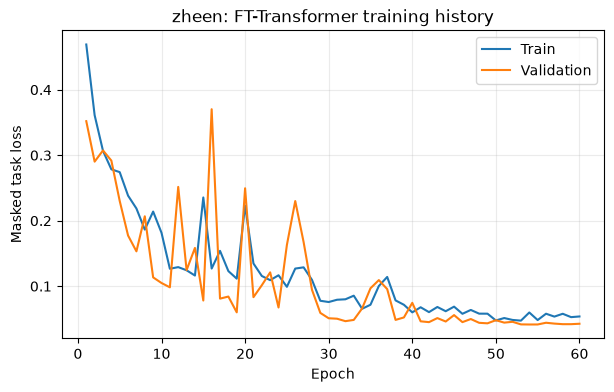

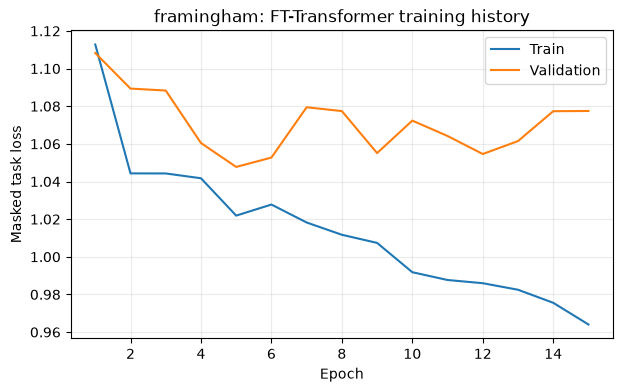

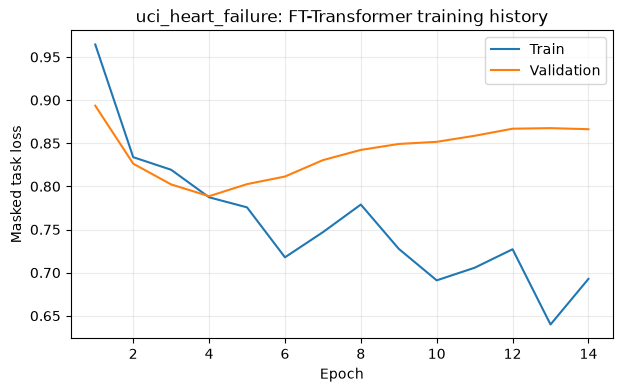

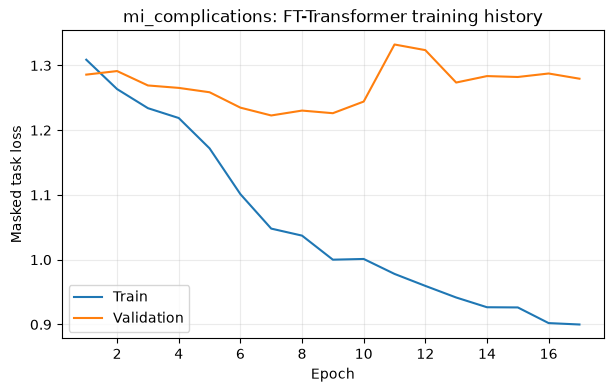

In [7]:
for source in SOURCES:
    history_path = ARTIFACT_ROOT / "ft_transformer" / source / "training_history.csv"
    if not history_path.is_file(): continue
    history = pd.read_csv(history_path)
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], label="Train")
    plt.plot(history["epoch"], history["validation_loss"], label="Validation")
    plt.title(f"{source}: FT-Transformer training history")
    plt.xlabel("Epoch"); plt.ylabel("Masked task loss"); plt.grid(alpha=0.25); plt.legend(); plt.show()

## 7. Interpretation and reproducibility limits

- These are four independent source-specific models, not one four-dataset model.
- The target semantics and training populations remain source-specific.
- Any row-level split must be reported as row-level; it is not patient-disjoint unless a verified identifier was used.
- Validation predictions may be used in a separate calibration notebook. Do not fit calibration on test predictions.
- Test metrics are not interchangeable between different outcomes or populations.
- No multimodal patient-level fusion model is trained because the six datasets are unpaired.